<a href="https://colab.research.google.com/github/msinha7370-sys/Laptop-Price-Prediction-ML-Model/blob/main/Laptop_Price_Prediction_ML_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
file_path = "/content/laptop.csv"
laptop_data = pd.read_csv(file_path)
laptop_data.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/laptop.csv'



---


**-------The dataset contains 1303 entries with 13 columns, but it seems there are two unnamed columns (Unnamed: 0.1 and Unnamed: 0) that likely serve as indexes and don't provide relevant information for our analysis. Here are the key features available in the dataset:---------**


---


**1. Company: The brand of the laptop.**

**2. TypeName: The type of laptop (e.g., Ultrabook, Notebook).**

**3. Inches: The size of the screen in inches.**

**4. ScreenResolution: The laptop's screen resolution.**

**5. Cpu: The CPU model.**

**6. Ram: The amount of RAM.**

**7. Memory: The type and size of the laptop's memory (e.g., SSD/HDD).**

**8. Gpu: The GPU model.**

**9. OpSys: The operating system.**

**10. Weight: The weight of the laptop.**

**11. Price: The price of the laptop, which is our target variable.**



---



In [ ]:
laptop_data['Memory'].value_counts()

256GB SSD                        401
1TB HDD                          217
500GB HDD                        130
512GB SSD                        116
128GB SSD +  1TB HDD              92
128GB SSD                         74
256GB SSD +  1TB HDD              71
32GB Flash Storage                37
2TB HDD                           16
64GB Flash Storage                14
512GB SSD +  1TB HDD              14
1TB SSD                           13
256GB SSD +  2TB HDD              10
1.0TB Hybrid                       9
256GB Flash Storage                8
16GB Flash Storage                 7
32GB SSD                           6
180GB SSD                          4
128GB Flash Storage                4
512GB SSD +  2TB HDD               3
16GB SSD                           3
512GB Flash Storage                2
1TB SSD +  1TB HDD                 2
128GB SSD +  2TB HDD               2
256GB SSD +  500GB HDD             2
256GB SSD +  256GB SSD             2
512GB SSD +  256GB SSD             1
5

In [ ]:
# prompt: Using dataframe laptop_data: collects details of data

laptop_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0.1      1303 non-null   int64  
 1   Unnamed: 0        1273 non-null   float64
 2   Company           1273 non-null   object 
 3   TypeName          1273 non-null   object 
 4   Inches            1273 non-null   object 
 5   ScreenResolution  1273 non-null   object 
 6   Cpu               1273 non-null   object 
 7   Ram               1273 non-null   object 
 8   Memory            1273 non-null   object 
 9   Gpu               1273 non-null   object 
 10  OpSys             1273 non-null   object 
 11  Weight            1273 non-null   object 
 12  Price             1273 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 132.5+ KB


In [ ]:
laptop_data.shape

(1303, 13)

In [ ]:
laptop_data.size

16939

In [ ]:
# prompt: Checking NULL Values in the DATA
laptop_data.isnull().sum()

Unnamed: 0.1         0
Unnamed: 0          30
Company             30
TypeName            30
Inches              30
ScreenResolution    30
Cpu                 30
Ram                 30
Memory              30
Gpu                 30
OpSys               30
Weight              30
Price               30
dtype: int64

In [ ]:
laptop_data.isnull().mean()*100

## SINCE THE DATA IS LESS THAN 5% WE WILL BE REMOVING IT

Unnamed: 0.1        0.000000
Unnamed: 0          2.302379
Company             2.302379
TypeName            2.302379
Inches              2.302379
ScreenResolution    2.302379
Cpu                 2.302379
Ram                 2.302379
Memory              2.302379
Gpu                 2.302379
OpSys               2.302379
Weight              2.302379
Price               2.302379
dtype: float64

In [ ]:
laptop_data.duplicated().sum()

0

**Removing NULL values From the data set.**
**There are 1273 non-null entries for most columns, indicating some missing data that we'll need to address. Additionally, the Inches and Weight columns are read as objects (strings) due to the presence of units (e.g., kg, inches), so we'll need to convert these to numerical values for analysis. The first step in preprocessing will involve cleaning these aspects:**

In [ ]:
# Step 1: Remove unnecessary unnamed columns
laptop_data_cleaned = laptop_data.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])

# Step 2: Handle missing values - for simplicity, we'll drop any rows with missing data
laptop_data_cleaned.dropna(inplace=True)

# Step 3: Convert 'Inches' and 'Weight' to numerical data types
# laptop_data_cleaned['Inches'] = laptop_data_cleaned['Inches'].astype(float)
# laptop_data_cleaned['Weight'] = laptop_data_cleaned['Weight'].str.replace('kg', '').astype(float)
'''An error has occured due to the presence of non-numeric number in inches and weights, Which is solved in next line.'''

# Check the dataset after cleaning
laptop_data_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1273 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1273 non-null   object 
 1   TypeName          1273 non-null   object 
 2   Inches            1273 non-null   object 
 3   ScreenResolution  1273 non-null   object 
 4   Cpu               1273 non-null   object 
 5   Ram               1273 non-null   object 
 6   Memory            1273 non-null   object 
 7   Gpu               1273 non-null   object 
 8   OpSys             1273 non-null   object 
 9   Weight            1273 non-null   object 
 10  Price             1273 non-null   float64
dtypes: float64(1), object(10)
memory usage: 119.3+ KB


In [ ]:
# Identify non-numeric values in 'Inches' and 'Weight' columns
non_numeric_inches = laptop_data_cleaned[pd.to_numeric(laptop_data_cleaned['Inches'], errors='coerce').isnull()]['Inches']
non_numeric_weight = laptop_data_cleaned[pd.to_numeric(laptop_data_cleaned['Weight'].str.replace('kg', ''), errors='coerce').isnull()]['Weight']

non_numeric_inches, non_numeric_weight




(476    ?
 Name: Inches, dtype: object,
 208    ?
 Name: Weight, dtype: object)

In [ ]:


# Remove rows with non-numeric values ('?') in 'Inches' and 'Weight' columns
laptop_data_cleaned = laptop_data_cleaned[~(laptop_data_cleaned['Inches'] == '?')]     ## ~ is used to convert bool value "True" to "False" and "False" to "True"
laptop_data_cleaned = laptop_data_cleaned[~(laptop_data_cleaned['Weight'] == '?')]

# Convert 'Inches' and 'Weight' to numerical data types again
laptop_data_cleaned['Inches'] = laptop_data_cleaned['Inches'].astype(float)
laptop_data_cleaned['Weight'] = laptop_data_cleaned['Weight'].str.replace('kg', '').astype(float)    ## Convert Inches DataType in to Float




In [ ]:
# Check the dataset after cleaning and conversion
print(laptop_data_cleaned.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1271 entries, 0 to 1302
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1271 non-null   object 
 1   TypeName          1271 non-null   object 
 2   Inches            1271 non-null   float64
 3   ScreenResolution  1271 non-null   object 
 4   Cpu               1271 non-null   object 
 5   Ram               1271 non-null   object 
 6   Memory            1271 non-null   object 
 7   Gpu               1271 non-null   object 
 8   OpSys             1271 non-null   object 
 9   Weight            1271 non-null   float64
 10  Price             1271 non-null   float64
dtypes: float64(3), object(8)
memory usage: 119.2+ KB
None


In [ ]:
laptop_data_cleaned

,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,71378.6832
1,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,47895.5232
2,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86,30636.0000
3,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83,135195.3360
4,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,96095.8080
...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.80,33992.6400
1299,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.30,79866.7200
1300,Lenovo,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.50,12201.1200
1301,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19,40705.9200


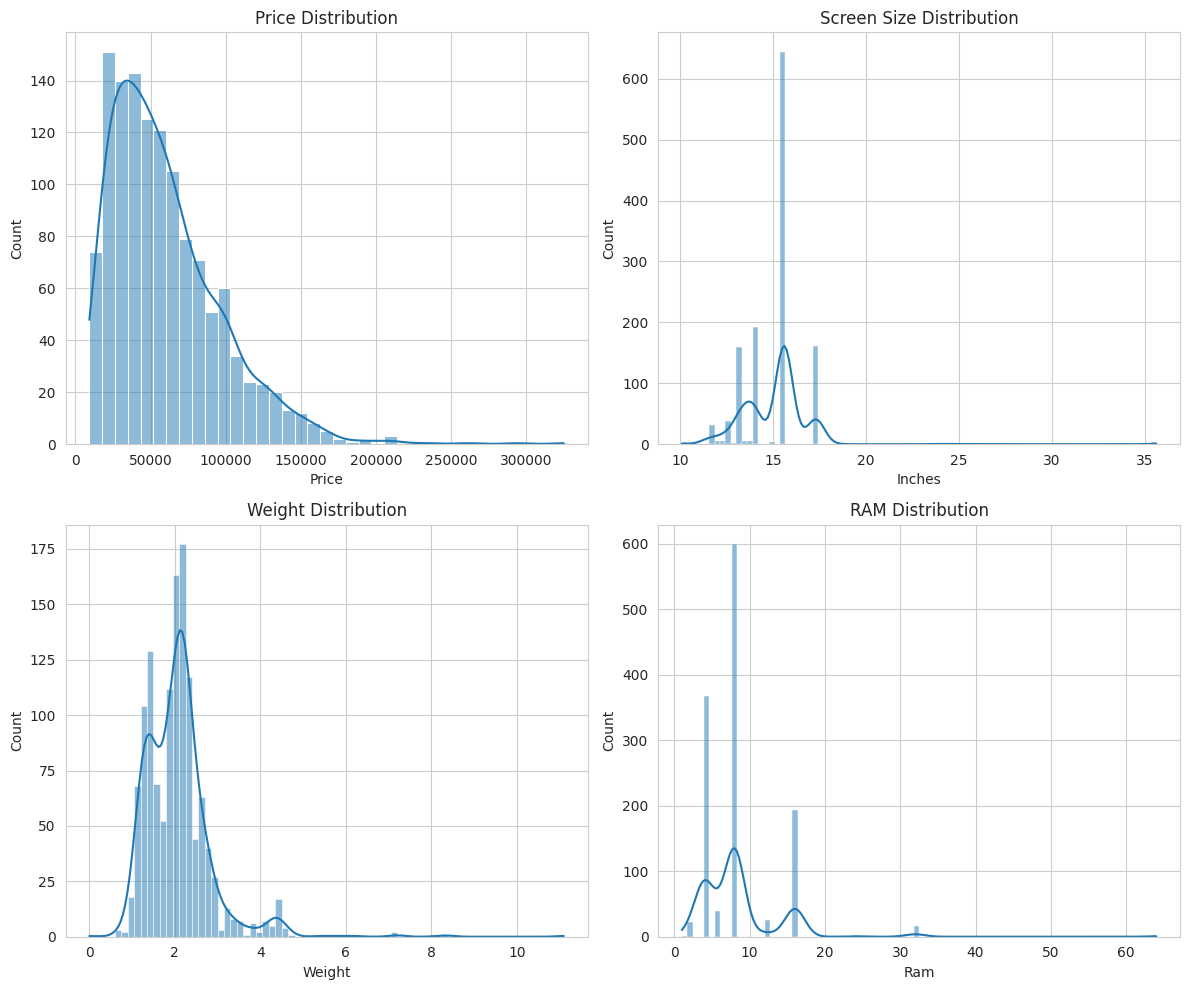

In [ ]:

# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Plot distributions of key numerical features
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Price distribution
sns.histplot(laptop_data_cleaned['Price'], kde=True, ax=axs[0, 0])
axs[0, 0].set_title('Price Distribution')

# Inches distribution
sns.histplot(laptop_data_cleaned['Inches'], kde=True, ax=axs[0, 1])
axs[0, 1].set_title('Screen Size Distribution')

# Weight distribution
sns.histplot(laptop_data_cleaned['Weight'], kde=True, ax=axs[1, 0])
axs[1, 0].set_title('Weight Distribution')

# Convert 'Ram' from string to numerical first for It we need to convert it as string type.
laptop_data_cleaned['Ram'] = laptop_data_cleaned['Ram'].astype(str)
laptop_data_cleaned['Ram'] = pd.to_numeric(laptop_data_cleaned['Ram'].str.replace('GB', ''))
sns.histplot(laptop_data_cleaned['Ram'], kde=True, ax=axs[1, 1])
axs[1, 1].set_title('RAM Distribution')

plt.tight_layout()
plt.show()




**Products whose price is between 20000-60000 have highest demand or sell**



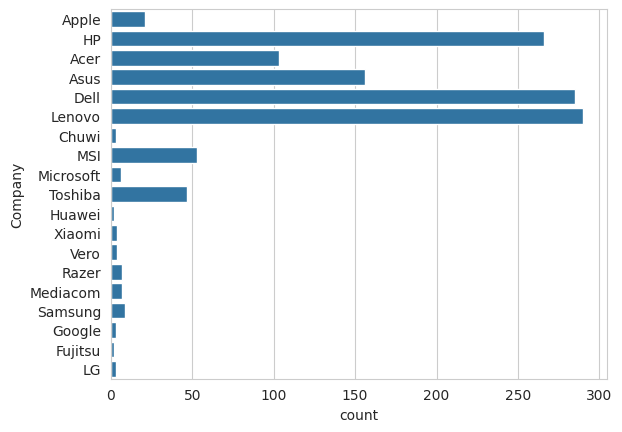

In [ ]:

sns.countplot(laptop_data_cleaned['Company'])
plt.show()

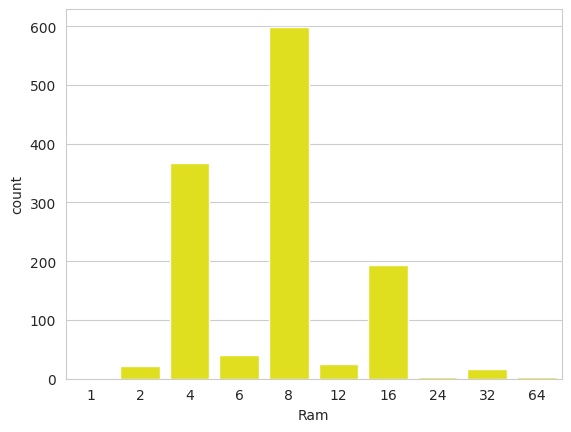

In [ ]:
sns.countplot(data = laptop_data_cleaned,x = 'Ram', color = 'yellow')
plt.show()

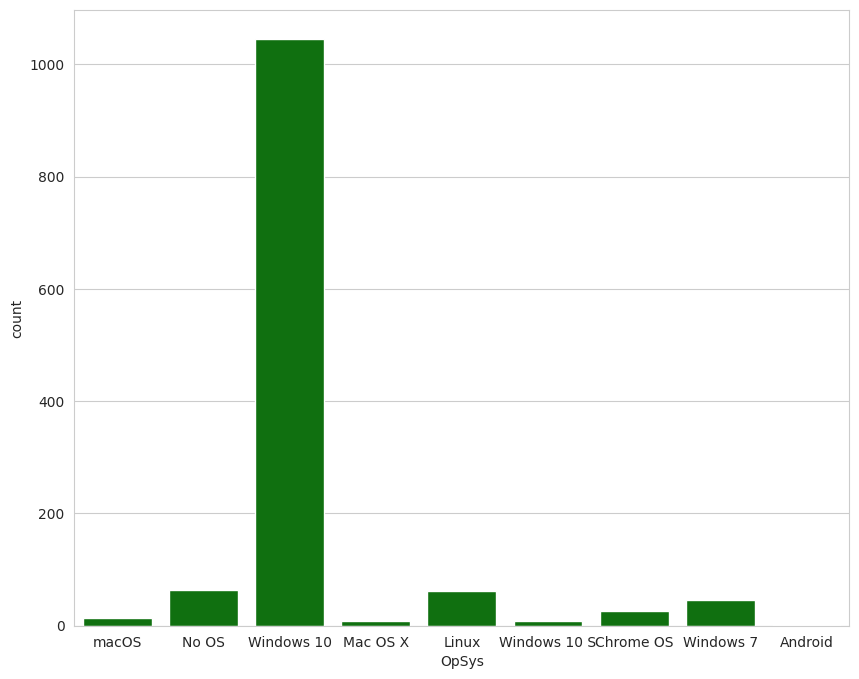

In [ ]:
plt.figure(figsize=(10,8))
sns.countplot(data = laptop_data_cleaned,x = 'OpSys', color = 'green')
plt.show()

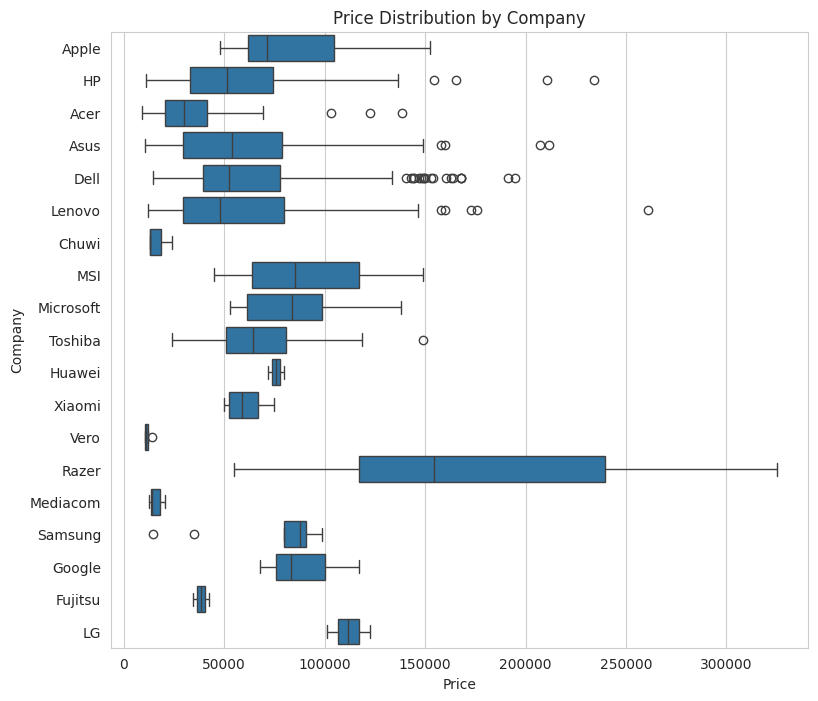

In [ ]:
# Boxplot to show price distribution across different Companies
plt.figure(figsize=(9, 8))
sns.boxplot(x='Price', y='Company', data=laptop_data_cleaned, orient='h')
plt.title('Price Distribution by Company')
plt.show()




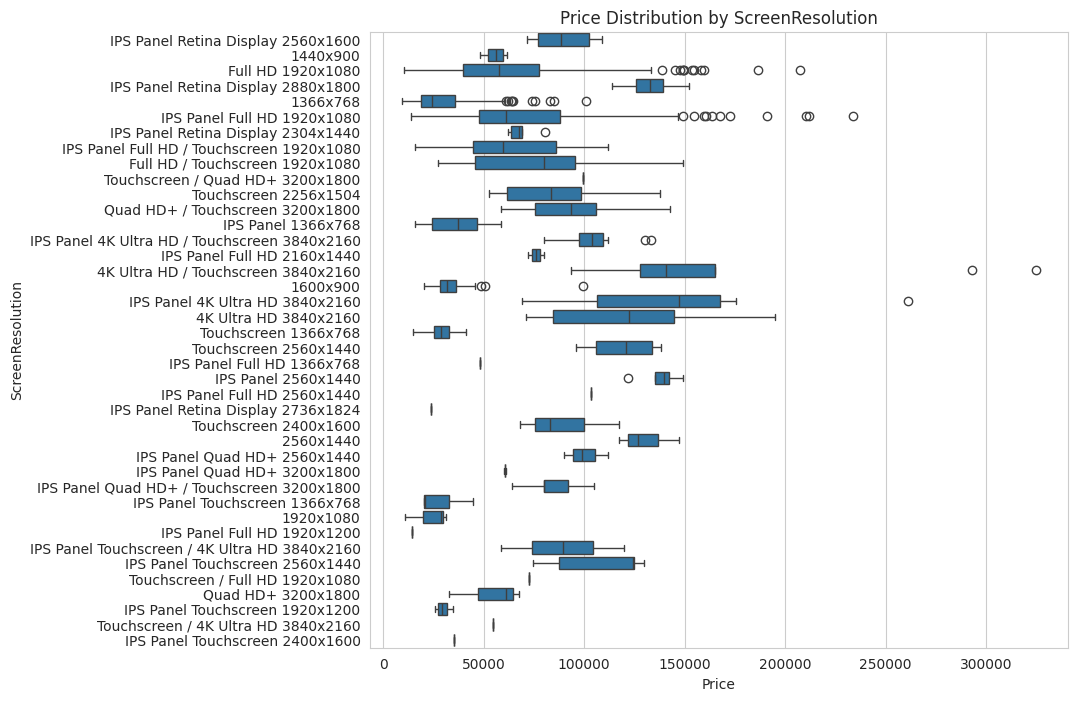

In [ ]:
plt.figure(figsize=(9, 8))
sns.boxplot(x='Price', y='ScreenResolution', data=laptop_data_cleaned, orient='h')
plt.title('Price Distribution by ScreenResolution')
plt.show()


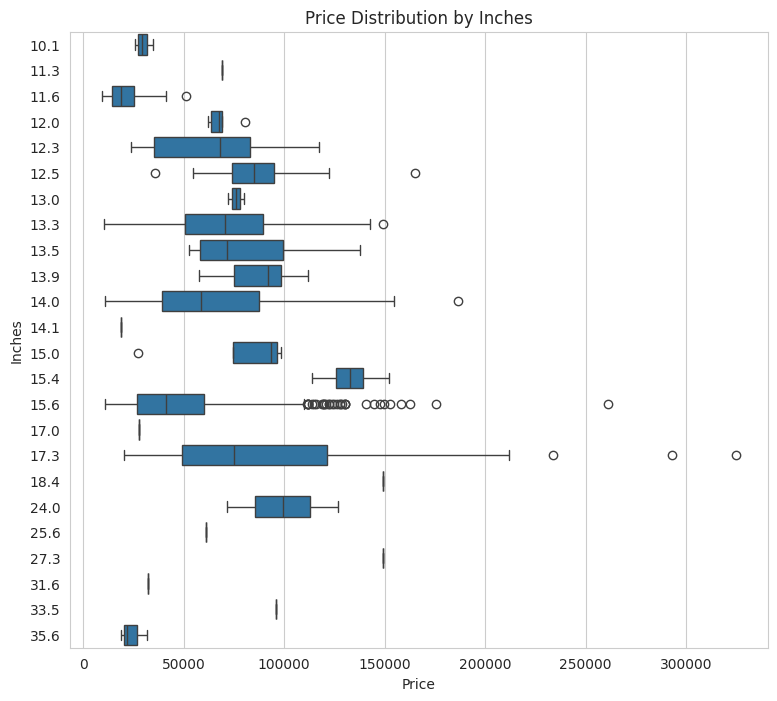

In [ ]:
plt.figure(figsize=(9, 8))
sns.boxplot(x='Price', y='Inches', data=laptop_data_cleaned, orient='h')
plt.title('Price Distribution by Inches')
plt.show()


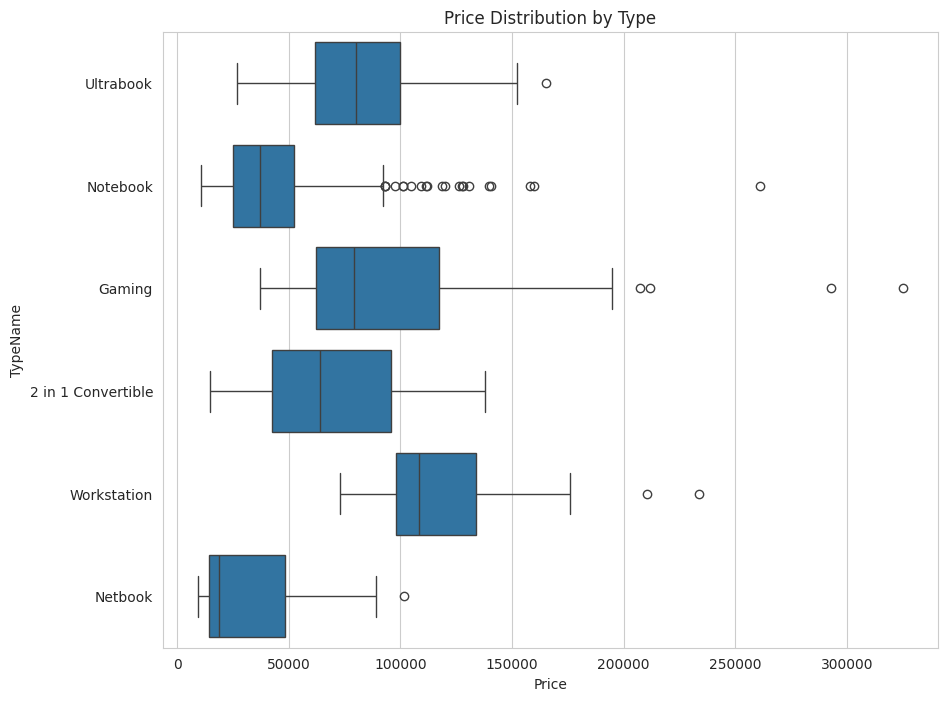

In [ ]:
# Boxplot to show price distribution across different Types
plt.figure(figsize=(10, 8))
sns.boxplot(x='Price', y='TypeName', data=laptop_data_cleaned, orient='h')
plt.title('Price Distribution by Type')
plt.show()

----------------------------------------------

-----------------------------------

**To prepare the dataset for modeling, we'll encode the categorical variables. This involves converting text data into a format that machine learning algorithms can work with. We have several categorical variables in our dataset, such as Company, TypeName, ScreenResolution, Cpu, Memory, Gpu, and OpSys.**

In [ ]:
from sklearn.preprocessing import OneHotEncoder

'''sparse=False: This tells the encoder to return a dense array instead of a sparse matrix. A dense array is a regular 2D array, while a sparse matrix only stores non-zero elements to save memory.
drop='first': This parameter is used to avoid the dummy variable trap, a scenario where variables are highly correlated. By dropping the first category, one category is always implied by the zeros in all the other categories, ensuring that the encoded features are independent.'''


# One-hot encoding for selected categorical variables
ohe_encoder = OneHotEncoder(sparse=False, drop='first') # Drop first to avoid dummy variable trap
encoded_columns = ohe_encoder.fit_transform(laptop_data_cleaned[['Company', 'TypeName', 'OpSys']])
encoded_col_names = ohe_encoder.get_feature_names_out(['Company', 'TypeName', 'OpSys'])

# Convert the encoded columns back to a DataFrame and concatenate with the original dataset
encoded_df = pd.DataFrame(encoded_columns, columns=encoded_col_names, index=laptop_data_cleaned.index)
laptop_data_prepared = pd.concat([laptop_data_cleaned.drop(['Company', 'TypeName', 'OpSys'], axis=1), encoded_df], axis=1)

# Quick check on the prepared dataset
laptop_data_prepared.info()


<class 'pandas.core.frame.DataFrame'>
Int64Index: 1271 entries, 0 to 1302
Data columns (total 39 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Inches                1271 non-null   float64
 1   ScreenResolution      1271 non-null   object 
 2   Cpu                   1271 non-null   object 
 3   Ram                   1271 non-null   int64  
 4   Memory                1271 non-null   object 
 5   Gpu                   1271 non-null   object 
 6   Weight                1271 non-null   float64
 7   Price                 1271 non-null   float64
 8   Company_Apple         1271 non-null   float64
 9   Company_Asus          1271 non-null   float64
 10  Company_Chuwi         1271 non-null   float64
 11  Company_Dell          1271 non-null   float64
 12  Company_Fujitsu       1271 non-null   float64
 13  Company_Google        1271 non-null   float64
 14  Company_HP            1271 non-null   float64
 15  Company_Huawei       

/usr/local/lib/python3.10/dist-packages/sklearn/preprocessing/_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


In [ ]:
laptop_data_prepared

,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,Weight,Price,Company_Apple,Company_Asus,...,TypeName_Ultrabook,TypeName_Workstation,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,1.37,71378.6832,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,1.34,47895.5232,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,1.86,30636.0000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,1.83,135195.3360,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,1.37,96095.8080,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4,128GB SSD,Intel HD Graphics 520,1.80,33992.6400,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1299,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16,512GB SSD,Intel HD Graphics 520,1.30,79866.7200,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1300,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2,64GB Flash Storage,Intel HD Graphics,1.50,12201.1200,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1301,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6,1TB HDD,AMD Radeon R5 M330,2.19,40705.9200,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
# Use pandas get_dummies for one-hot encoding as an alternative approach
'''This code snippet illustrates an alternative approach to one-hot encoding categorical variables using pandas' built-in function get_dummies.
This function is particularly convenient for encoding, as it operates directly on the pandas DataFrame,
transforming specified categorical columns into one-hot encoded variables. Let's break down the process:'''

laptop_data_encoded = pd.get_dummies(laptop_data_cleaned, columns=['Company', 'TypeName', 'OpSys'], drop_first=True)

# Check the dataset after encoding
laptop_data_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1271 entries, 0 to 1302
Data columns (total 39 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Inches                1271 non-null   float64
 1   ScreenResolution      1271 non-null   object 
 2   Cpu                   1271 non-null   object 
 3   Ram                   1271 non-null   int64  
 4   Memory                1271 non-null   object 
 5   Gpu                   1271 non-null   object 
 6   Weight                1271 non-null   float64
 7   Price                 1271 non-null   float64
 8   Company_Apple         1271 non-null   uint8  
 9   Company_Asus          1271 non-null   uint8  
 10  Company_Chuwi         1271 non-null   uint8  
 11  Company_Dell          1271 non-null   uint8  
 12  Company_Fujitsu       1271 non-null   uint8  
 13  Company_Google        1271 non-null   uint8  
 14  Company_HP            1271 non-null   uint8  
 15  Company_Huawei       

In [ ]:
laptop_data_encoded.head()


,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,Weight,Price,Company_Apple,Company_Asus,...,TypeName_Ultrabook,TypeName_Workstation,OpSys_Chrome OS,OpSys_Linux,OpSys_Mac OS X,OpSys_No OS,OpSys_Windows 10,OpSys_Windows 10 S,OpSys_Windows 7,OpSys_macOS
0,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,1.37,71378.6832,1,0,...,1,0,0,0,0,0,0,0,0,1
1,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,1.34,47895.5232,1,0,...,1,0,0,0,0,0,0,0,0,1
2,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,1.86,30636.0000,0,0,...,0,0,0,0,0,1,0,0,0,0
3,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,1.83,135195.3360,1,0,...,1,0,0,0,0,0,0,0,0,1
4,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,1.37,96095.8080,1,0,...,1,0,0,0,0,0,0,0,0,1


<Axes: xlabel='Inches', ylabel='Price'>

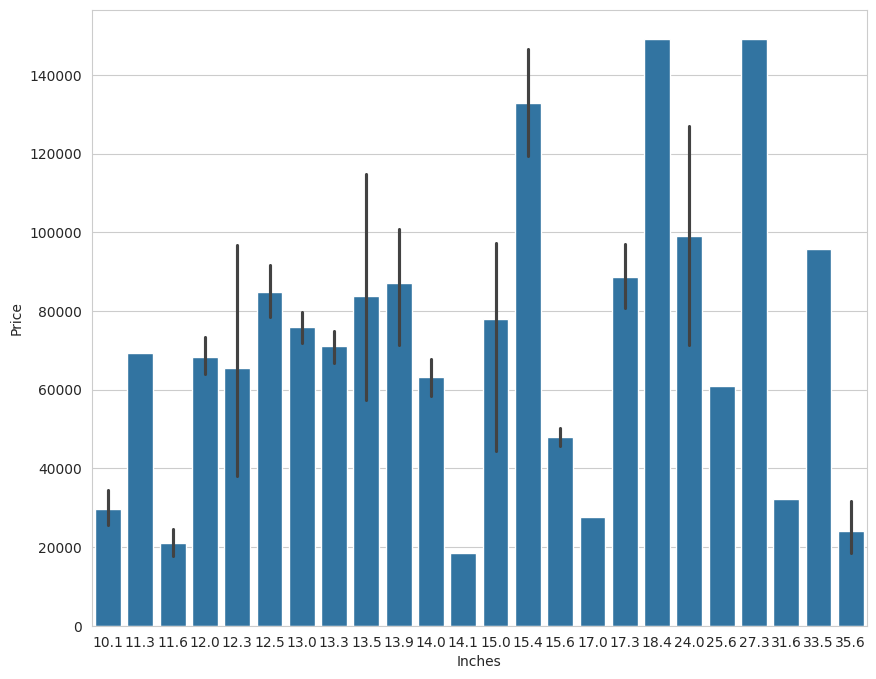

In [ ]:
# Set the figure size
plt.figure(figsize=(10, 8))
sns.barplot(data = laptop_data_prepared, y = 'Price', x = 'Inches')

In [ ]:
# Print unique values in the ScreenResolution column
unique_screen_resolutions = laptop_data_cleaned['ScreenResolution'].unique()
print(pd.DataFrame(unique_screen_resolutions))

                                                0
0              IPS Panel Retina Display 2560x1600
1                                        1440x900
2                               Full HD 1920x1080
3              IPS Panel Retina Display 2880x1800
4                                        1366x768
5                     IPS Panel Full HD 1920x1080
6              IPS Panel Retina Display 2304x1440
7       IPS Panel Full HD / Touchscreen 1920x1080
8                 Full HD / Touchscreen 1920x1080
9                Touchscreen / Quad HD+ 3200x1800
10                          Touchscreen 2256x1504
11               Quad HD+ / Touchscreen 3200x1800
12                             IPS Panel 1366x768
13  IPS Panel 4K Ultra HD / Touchscreen 3840x2160
14                    IPS Panel Full HD 2160x1440
15            4K Ultra HD / Touchscreen 3840x2160
16                                       1600x900
17                IPS Panel 4K Ultra HD 3840x2160
18                          4K Ultra HD 3840x2160


In [ ]:
unique_Cpu = laptop_data_cleaned['Cpu'].unique()
print(pd.DataFrame(unique_Cpu))

                                      0
0                  Intel Core i5 2.3GHz
1                  Intel Core i5 1.8GHz
2            Intel Core i5 7200U 2.5GHz
3                  Intel Core i7 2.7GHz
4                  Intel Core i5 3.1GHz
..                                  ...
113  Intel Celeron Dual Core N3350 2GHz
114       Samsung Cortex A72&A53 2.0GHz
115            AMD E-Series 9000 2.2GHz
116            Intel Core M 6Y30 0.9GHz
117           AMD A9-Series 9410 2.9GHz

[118 rows x 1 columns]


In [ ]:
AMD = laptop_data_prepared['Cpu'].apply(lambda x: 1 if 'AMD' in x else 0).value_counts()
AMD

0    1209
1      62
Name: Cpu, dtype: int64

In [ ]:
Intel = laptop_data_prepared['Cpu'].apply(lambda x: 1 if 'Intel' in x else 0).value_counts()
Intel

1    1208
0      63
Name: Cpu, dtype: int64

In [ ]:
total_cpu_com = laptop_data_prepared['Cpu'].apply(lambda x: 'Intel' if 'Intel' in x else ('AMD' if 'AMD' in x else x)).value_counts()
total_cpu_com

Intel                            1208
AMD                                62
Samsung Cortex A72&A53 2.0GHz       1
Name: Cpu, dtype: int64

In [ ]:
Gpu = laptop_data_prepared['Gpu'].apply(lambda x: 'Nvidia' if 'Nvidia' in x else ('AMD' if 'AMD' in x else ('Intel' if 'Intel' in x else x))).value_counts()
Gpu

Intel                702
Nvidia               392
AMD                  176
ARM Mali T860 MP4      1
Name: Gpu, dtype: int64

In [ ]:
laptop_data_prepared['Memory'].value_counts()

256GB SSD                        399
1TB HDD                          217
500GB HDD                        130
512GB SSD                        116
128GB SSD +  1TB HDD              92
128GB SSD                         74
256GB SSD +  1TB HDD              71
32GB Flash Storage                37
2TB HDD                           16
64GB Flash Storage                14
512GB SSD +  1TB HDD              14
1TB SSD                           13
256GB SSD +  2TB HDD              10
1.0TB Hybrid                       9
256GB Flash Storage                8
16GB Flash Storage                 7
32GB SSD                           6
180GB SSD                          4
128GB Flash Storage                4
512GB SSD +  2TB HDD               3
16GB SSD                           3
512GB Flash Storage                2
1TB SSD +  1TB HDD                 2
128GB SSD +  2TB HDD               2
256GB SSD +  500GB HDD             2
256GB SSD +  256GB SSD             2
512GB SSD +  256GB SSD             1
5

In [ ]:
laptop_data['Cpu'].value_counts()

Intel Core i5 7200U 2.5GHz     183
Intel Core i7 7700HQ 2.8GHz    142
Intel Core i7 7500U 2.7GHz     128
Intel Core i7 8550U 1.8GHz      72
Intel Core i5 8250U 1.6GHz      68
                              ... 
AMD A9-Series 9420 2.9GHz        1
Intel Core i7 2.2GHz             1
AMD A6-Series 7310 2GHz          1
Intel Atom Z8350 1.92GHz         1
AMD E-Series 9000e 1.5GHz        1
Name: Cpu, Length: 118, dtype: int64

In [ ]:
# unique_memory_configurations = laptop_data_prepared['Memory'].unique()
# pd.DataFrame(unique_memory_configurations)


,0
0,128GB SSD
1,128GB Flash Storage
2,256GB SSD
3,512GB SSD
4,500GB HDD
5,256GB Flash Storage
6,1TB HDD
7,128GB SSD + 1TB HDD
8,256GB SSD + 256GB SSD
9,64GB Flash Storage


In [ ]:
# Feature Engineering on ScreenResolution, Cpu, and Gpu

# Screen Resolution: Extract resolution and whether it's IPS and/or Retina
laptop_data_prepared['Resolution_Width'] = laptop_data_prepared['ScreenResolution'].apply(lambda x: int(x.split('x')[0].split()[-1]))
laptop_data_prepared['Resolution_Height'] = laptop_data_prepared['ScreenResolution'].apply(lambda x: int(x.split('x')[1]))
laptop_data_prepared['IPS_Panel'] = laptop_data_prepared['ScreenResolution'].apply(lambda x: 1 if 'IPS' in x else 0)
laptop_data_prepared['Retina_Display'] = laptop_data_prepared['ScreenResolution'].apply(lambda x: 1 if 'Retina' in x else 0)
laptop_data_prepared['Touch_Screen'] = laptop_data_prepared['ScreenResolution'].apply(lambda x: 1 if 'Touchscreen' in x else 0)
laptop_data_prepared['4K_Ultra_HD_Display'] = laptop_data_prepared['ScreenResolution'].apply(lambda x: 1 if '4K Ultra HD' in x else 0)
laptop_data_prepared['Full_HD_Display'] = laptop_data_prepared['ScreenResolution'].apply(lambda x: 1 if 'Full HD' in x else 0)
laptop_data_prepared['Quad_HD+_Display'] = laptop_data_prepared['ScreenResolution'].apply(lambda x: 1 if 'Quad HD+' in x else 0)


# CPU: Extract GHz and categorize by brand and type
laptop_data_prepared['Cpu_Speed_GHz'] = laptop_data_prepared['Cpu'].apply(lambda x: float(x.split()[-1].replace('GHz', '')) if 'GHz' in x else 0)
laptop_data_prepared['Cpu_Brand'] = laptop_data_prepared['Cpu'].apply(lambda x: 'Intel' if 'Intel' in x else ('AMD' if 'AMD' in x else 'Other'))
laptop_data_prepared['Cpu_Type'] = laptop_data_prepared['Cpu'].apply(lambda x: x.split()[0] if x.split()[0] in ['i3', 'i5', 'i7', 'i9'] else 'Other')

# GPU: Categorize by brand
laptop_data_prepared['Gpu_Brand'] = laptop_data_prepared['Gpu'].apply(lambda x: 'Nvidia' if 'Nvidia' in x else ('AMD' if 'AMD' in x else ('Intel' if 'Intel' in x else 'Other')))

# Drop the original columns to simplify the dataset
laptop_data_fe = laptop_data_prepared.drop(['ScreenResolution', 'Cpu', 'Gpu'], axis=1)

# Quick check on the dataset after feature engineering
laptop_data_fe.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1271 entries, 0 to 1302
Data columns (total 48 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Inches                1271 non-null   float64
 1   Ram                   1271 non-null   int64  
 2   Memory                1271 non-null   object 
 3   Weight                1271 non-null   float64
 4   Price                 1271 non-null   float64
 5   Company_Apple         1271 non-null   float64
 6   Company_Asus          1271 non-null   float64
 7   Company_Chuwi         1271 non-null   float64
 8   Company_Dell          1271 non-null   float64
 9   Company_Fujitsu       1271 non-null   float64
 10  Company_Google        1271 non-null   float64
 11  Company_HP            1271 non-null   float64
 12  Company_Huawei        1271 non-null   float64
 13  Company_LG            1271 non-null   float64
 14  Company_Lenovo        1271 non-null   float64
 15  Company_MSI          

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
laptop_data_fe['encoded_cpu_brand'] = encoder.fit_transform(laptop_data_fe['Cpu_Brand'])
laptop_data_fe['encoded_cpu_type'] = encoder.fit_transform(laptop_data_fe['Cpu_Type'])
laptop_data_fe['encoded_memory'] = encoder.fit_transform(laptop_data_fe['Memory'])
laptop_data_fe['encoded_gpu_brand'] = encoder.fit_transform(laptop_data_fe['Gpu_Brand'])

laptop_data_fe_final = laptop_data_fe.drop(['Gpu_Brand','Cpu_Brand','Cpu_Type','Memory',820,368,72,10,1],axis=1)
laptop_data_fe_final.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1271 entries, 0 to 1302
Data columns (total 48 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Inches                1271 non-null   float64
 1   Ram                   1271 non-null   int64  
 2   Weight                1271 non-null   float64
 3   Price                 1271 non-null   float64
 4   Company_Apple         1271 non-null   float64
 5   Company_Asus          1271 non-null   float64
 6   Company_Chuwi         1271 non-null   float64
 7   Company_Dell          1271 non-null   float64
 8   Company_Fujitsu       1271 non-null   float64
 9   Company_Google        1271 non-null   float64
 10  Company_HP            1271 non-null   float64
 11  Company_Huawei        1271 non-null   float64
 12  Company_LG            1271 non-null   float64
 13  Company_Lenovo        1271 non-null   float64
 14  Company_MSI           1271 non-null   float64
 15  Company_Mediacom     

In [ ]:
laptop_data_fe['Cpu_Type'].value_counts()

Other    1271
Name: Cpu_Type, dtype: int64

In [ ]:

laptop_data_fe['Cpu_Brand'].value_counts()

Intel    1208
AMD        62
Other       1
Name: Cpu_Brand, dtype: int64

In [ ]:
laptop_data_fe['encoded_cpu_brand'].value_counts()

1    1208
0      62
2       1
Name: encoded_cpu_brand, dtype: int64

SSD        820
HDD        368
Flash       72
Hybride     10
?            1
Name: Memory, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn import metrics
from sklearn.metrics import mean_squared_error

x = laptop_data_fe_final.drop(columns=['Price'])
y = laptop_data_fe_final['Price']


x.head()

NameError: name 'lin_reg' is not defined

In [ ]:
y.head()

0     71378.6832
1     47895.5232
2     30636.0000
3    135195.3360
4     96095.8080
Name: Price, dtype: float64

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size =0.2,random_state= 1)

In [ ]:
reg = linear_model.LinearRegression()
reg.fit(x_train,y_train)
y_pred = reg.predict(x_test)

In [ ]:
print('Cofficient:',reg.coef_)

Cofficient: [-4.40282364e+02  2.28283581e+03  3.43338424e+03  2.30258743e+04
  3.58976600e+03 -2.13145029e+04  7.30517764e+03 -9.20408638e-10
  7.80504454e+04  9.85255041e+03  5.41070383e+04  4.42553560e+04
  5.07864809e+03  1.16388011e+04 -9.87109824e+03  6.32541567e+04
  4.74432664e+04  1.67750425e+04  1.81179079e+04 -1.85811447e+04
  1.27464475e+04  1.92391097e+03 -3.19320760e+03 -1.28035875e+04
  2.94087622e+03  3.07229063e+04 -9.67416368e+03 -9.63858255e+03
  9.30851873e+03 -1.47510681e+04 -1.49315247e+03 -5.77268804e+03
  1.83037806e+04  1.37173555e+04  1.79736869e+02 -2.43428139e+02
  1.34451569e+03 -9.42000050e+03 -5.83802453e+02 -6.03815101e+04
 -1.06408599e+04 -5.12775182e+04  1.03941438e+04  1.39011358e+04
  0.00000000e+00  3.79919198e+02  1.50110252e+03]


In [ ]:
# variance score: 1 means perfect prediction
print('Variance score: {}'.format(reg.score(x_test, y_test)))

Variance score: 0.7795254669635727


In [ ]:
reg.score(x_train,y_train)

0.7405216927378218

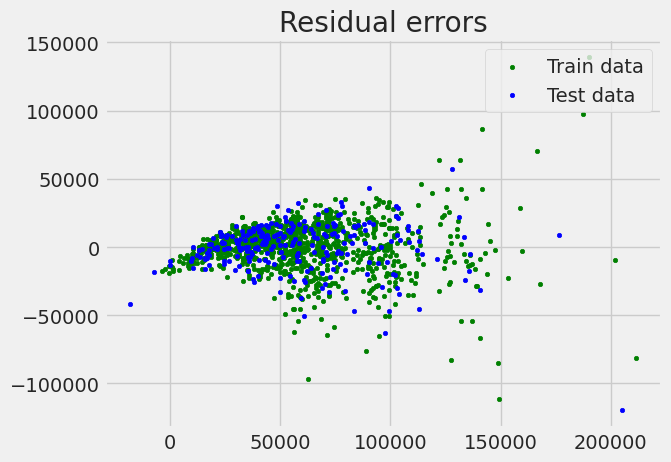

In [ ]:
# plot for residual error

# setting plot style
plt.style.use('fivethirtyeight')
# plotting residual errors in training data
plt.scatter(reg.predict(x_train),reg.predict(x_train) - y_train, color="green", s=10, label='Train data')
# plotting residual errors in test data
plt.scatter(reg.predict(x_test),
            reg.predict(x_test) - y_test,
            color="blue", s=10,
            label='Test data')

# plotting line for zero residual error
plt.hlines(y=0, xmin=0, xmax=50, linewidth=2)

# plotting legend
plt.legend(loc='upper right')

# plot title
plt.title("Residual errors")

# method cal
plt.show()

In [ ]:
print('Mean_ab_er:', metrics.mean_absolute_error(y_test,y_pred))
print('MEAN_sq_er:',metrics.mean_squared_error(y_test,y_pred))
print('RMSE:',np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

Mean_ab_er: 12848.508132020343
MEAN_sq_er: 323604038.518343
RMSE: 17988.997707441707


In [ ]:
|